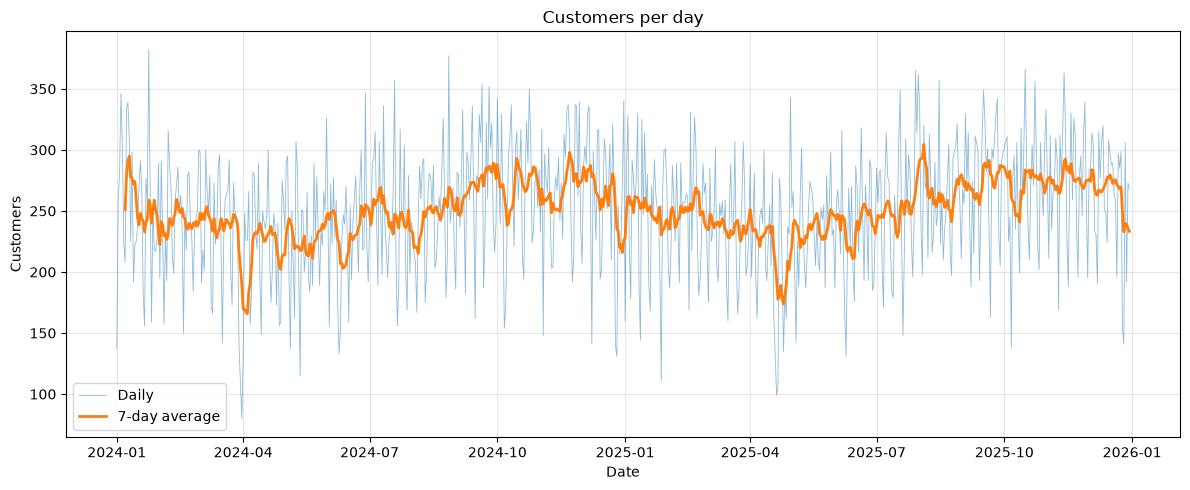

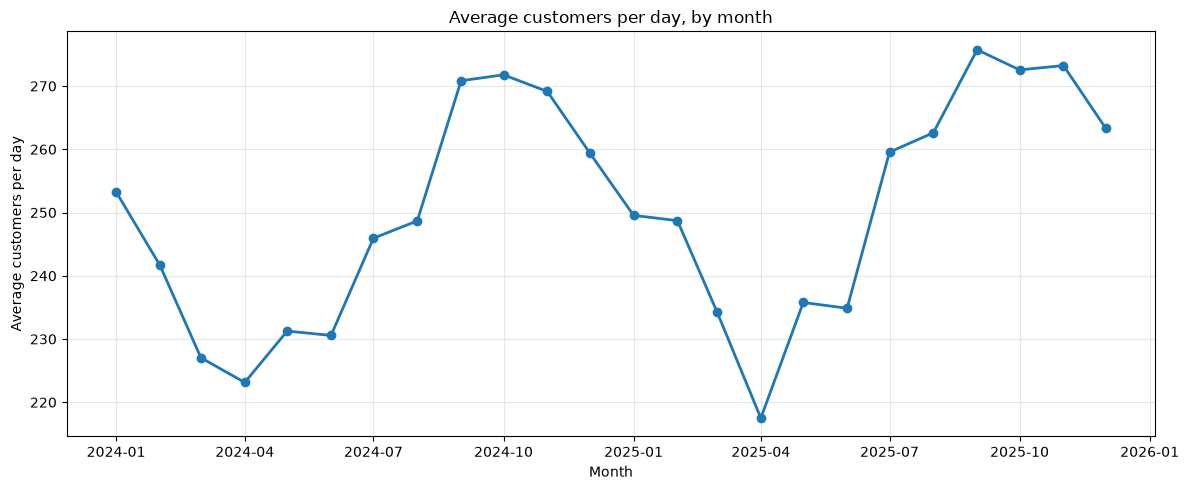

In [2]:
import polars as pl
import matplotlib.pyplot as plt

# Load the simulated customer counts (path is relative to sim/notebook/)
df = pl.read_parquet("../../data/raw/base_seed42/hourly_customers.parquet")

# ---------- Customers per day ----------

# Add up all the hours in each day to get one total per day.
daily = (
    df.group_by("date")
    .agg(pl.col("customers").sum())
    .sort("date")
    # A 7-day rolling average smooths out the weekday/weekend pattern,
    # making the seasonal wave and growth trend easier to see.
    .with_columns(pl.col("customers").rolling_mean(window_size=7).alias("avg_7_day"))
)

plt.figure(figsize=(12, 5))
plt.plot(daily["date"], daily["customers"], linewidth=0.6, alpha=0.5, label="Daily")
plt.plot(daily["date"], daily["avg_7_day"], linewidth=2, label="7-day average")
plt.title("Customers per day")
plt.xlabel("Date")
plt.ylabel("Customers")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---------- Average customers per day, by month ----------

# Group the daily totals by month, then average them. We average rather
# than sum because months have different numbers of days.
monthly = (
    daily.with_columns(pl.col("date").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg(pl.col("customers").mean().alias("avg_customers_per_day"))
    .sort("month")
)

plt.figure(figsize=(12, 5))
plt.plot(monthly["month"], monthly["avg_customers_per_day"], marker="o", linewidth=2)
plt.title("Average customers per day, by month")
plt.xlabel("Month")
plt.ylabel("Average customers per day")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()